In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score

In [2]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Dataset shape:", X.shape)
print(X.head())
print(y.head())

Dataset shape: (569, 30)
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst 

In [3]:
print("Missing values:")
print(X.isnull().sum().sum())

print("\nTarget classes:")
print(y.value_counts())

Missing values:
0

Target classes:
target
1    357
0    212
Name: count, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (455, 30)
Testing data: (114, 30)


In [5]:
depths = [2, 4, 6, 8, 10]

results_depth = []

for depth in depths:
    model = RandomForestClassifier(
        n_estimators=100,
        max_depth=depth,
        random_state=42
    )
    
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    
    results_depth.append([
        depth, accuracy, precision, recall
    ])

depth_results = pd.DataFrame(
    results_depth,
    columns=["Max Depth", "Accuracy", "Precision", "Recall"]
)

depth_results

,Max Depth,Accuracy,Precision,Recall
0,2,0.947368,0.958333,0.958333
1,4,0.956140,0.958904,0.972222
2,6,0.947368,0.958333,0.958333
3,8,0.956140,0.958904,0.972222
4,10,0.956140,0.958904,0.972222


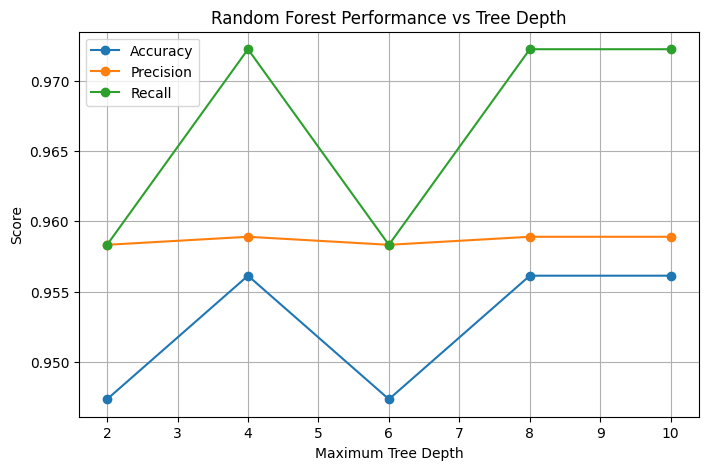

In [6]:
plt.figure(figsize=(8, 5))

plt.plot(
    depth_results["Max Depth"],
    depth_results["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    depth_results["Max Depth"],
    depth_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    depth_results["Max Depth"],
    depth_results["Recall"],
    marker="o",
    label="Recall"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Score")
plt.title("Random Forest Performance vs Tree Depth")
plt.legend()
plt.grid(True)

plt.show()

In [7]:
tree_numbers = [10, 25, 50, 100, 150, 200]

results_trees = []

for n in tree_numbers:
    model = RandomForestClassifier(
        n_estimators=n,
        max_depth=6,
        random_state=42
    )
    
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    
    results_trees.append([
        n, accuracy, precision, recall
    ])

tree_results = pd.DataFrame(
    results_trees,
    columns=["Number of Trees", "Accuracy", "Precision", "Recall"]
)

tree_results

,Number of Trees,Accuracy,Precision,Recall
0,10,0.947368,0.958333,0.958333
1,25,0.956140,0.958904,0.972222
2,50,0.956140,0.958904,0.972222
3,100,0.947368,0.958333,0.958333
4,150,0.947368,0.958333,0.958333
5,200,0.947368,0.958333,0.958333


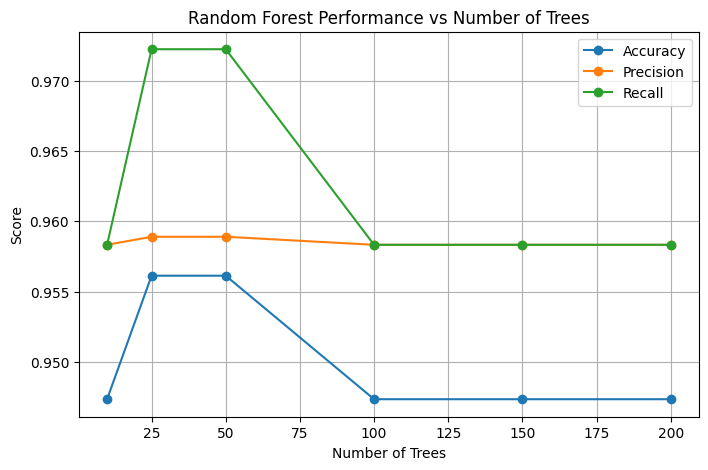

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(
    tree_results["Number of Trees"],
    tree_results["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    tree_results["Number of Trees"],
    tree_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    tree_results["Number of Trees"],
    tree_results["Recall"],
    marker="o",
    label="Recall"
)

plt.xlabel("Number of Trees")
plt.ylabel("Score")
plt.title("Random Forest Performance vs Number of Trees")
plt.legend()
plt.grid(True)

plt.show()

In [9]:
print("Results for different tree depths:")
display(depth_results)

print("\nResults for different numbers of trees:")
display(tree_results)

Results for different tree depths:


,Max Depth,Accuracy,Precision,Recall
0,2,0.947368,0.958333,0.958333
1,4,0.956140,0.958904,0.972222
2,6,0.947368,0.958333,0.958333
3,8,0.956140,0.958904,0.972222
4,10,0.956140,0.958904,0.972222



Results for different numbers of trees:


,Number of Trees,Accuracy,Precision,Recall
0,10,0.947368,0.958333,0.958333
1,25,0.956140,0.958904,0.972222
2,50,0.956140,0.958904,0.972222
3,100,0.947368,0.958333,0.958333
4,150,0.947368,0.958333,0.958333
5,200,0.947368,0.958333,0.958333


In [10]:
best_depth = depth_results.loc[
    depth_results["Accuracy"].idxmax()
]

best_trees = tree_results.loc[
    tree_results["Accuracy"].idxmax()
]

print("Best result based on tree depth:")
print(best_depth)

print("\nBest result based on number of trees:")
print(best_trees)

Best result based on tree depth:
Max Depth    4.000000
Accuracy     0.956140
Precision    0.958904
Recall       0.972222
Name: 1, dtype: float64

Best result based on number of trees:
Number of Trees    25.000000
Accuracy            0.956140
Precision           0.958904
Recall              0.972222
Name: 1, dtype: float64


In [11]:
final_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    random_state=42
)

final_model.fit(X_train, y_train)

final_prediction = final_model.predict(X_test)

print("Final Accuracy:",
      accuracy_score(y_test, final_prediction))

print("Final Precision:",
      precision_score(y_test, final_prediction))

print("Final Recall:",
      recall_score(y_test, final_prediction))

Final Accuracy: 0.9473684210526315
Final Precision: 0.9583333333333334
Final Recall: 0.9583333333333334
